# Part B – Step 9: H2O AutoML (repeat Steps 2–5)

Requires Java (see README). `h2o.init()` starts a local H2O server; its Flow UI is at http://localhost:54321.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import h2o
from h2o.automl import H2OAutoML
from sklearn.model_selection import train_test_split

from data_prep import load_athletes, TARGET

SEED = 30
MAX_RUNTIME_SECS = 300      # time budget per AutoML run
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

h2o.init(max_mem_size="4G")

Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
  Java Version: openjdk version "17.0.20.1" 2026-08-18; OpenJDK Runtime Environment Homebrew (build 17.0.20.1+0); OpenJDK 64-Bit Server VM Homebrew (build 17.0.20.1+0, mixed mode, sharing)
  Starting server from /Users/johnhenryoliphant/miniconda3/envs/automl/lib/python3.11/site-packages/h2o/backend/bin/h2o.jar
  Ice root: /var/folders/lk/13t_409j1hb1q53377xp8twr0000gn/T/tmpsmh0ce42
  JVM stdout: /var/folders/lk/13t_409j1hb1q53377xp8twr0000gn/T/tmpsmh0ce42/h2o_johnhenryoliphant_started_from_python.out
  JVM stderr: /var/folders/lk/13t_409j1hb1q53377xp8twr0000gn/T/tmpsmh0ce42/h2o_johnhenryoliphant_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.


H2O_cluster_uptime:,03 secs
H2O_cluster_timezone:,America/Chicago
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.12
H2O_cluster_version_age:,2 months and 28 days
H2O_cluster_name:,H2O_from_python_johnhenryoliphant_wwuqns
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,4 Gb
H2O_cluster_total_cores:,8
H2O_cluster_allowed_cores:,8
H2O_cluster_status:,"locked, healthy"



+------------------------------------------------------------------+
| You are running the community edition of H2O-3 OSS.              |
|                                                                  |
| For commercial use, H2O-3 Secure is now recommended.             |
| This includes production support, CVE fixes, multi-node scaling, |
| model artifact extraction, and more.                             |
| See h2o.ai/h2o-3/oss-vs-secure for additional details.           |
| Contact enterprise@h2o.ai to upgrade.                            |
+------------------------------------------------------------------+


## Load the same dataset (same cleaning and 80/20 split as PyCaret)

In [2]:
df = load_athletes()
train_df, test_df = train_test_split(df, test_size=0.2, random_state=SEED)

hf_train = h2o.H2OFrame(train_df)
hf_test = h2o.H2OFrame(test_df)
all_features = [c for c in df.columns if c != TARGET]
print(hf_train.shape, hf_test.shape)

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
(24665, 69) (6167, 69)


## 2. AutoML – find the best model (all features)

In [3]:
def run_automl(features, project):
    aml = H2OAutoML(max_runtime_secs=MAX_RUNTIME_SECS, nfolds=5, seed=SEED,
                    sort_metric="RMSE", project_name=project)
    aml.train(x=features, y=TARGET, training_frame=hf_train)
    lb = aml.leaderboard.as_data_frame()
    return aml, lb

aml_all, lb_all = run_automl(all_features, "athletes_h2o_all_features")
lb_all.to_csv(RESULTS / "h2o_leaderboard_all_features.csv", index=False)
print("Best model:", aml_all.leader.model_id)
lb_all

AutoML progress: |
20:08:53.207: AutoML: XGBoost is not available; skipping it.
20:08:53.279: _train param, Dropping bad and constant columns: [howlong_1_2_years_2_4_years_4_years]

███
20:08:58.504: _train param, Dropping bad and constant columns: [howlong_1_2_years_2_4_years_4_years]

████
20:09:21.643: _train param, Dropping unused columns: [howlong_1_2_years_2_4_years_4_years]
20:09:22.355: _train param, Dropping bad and constant columns: [howlong_1_2_years_2_4_years_4_years]

███████
20:09:57.886: _train param, Dropping bad and constant columns: [howlong_1_2_years_2_4_years_4_years]

████
20:10:15.271: _train param, Dropping bad and constant columns: [howlong_1_2_years_2_4_years_4_years]

████
20:10:34.32: _train param, Dropping bad and constant columns: [howlong_1_2_years_2_4_years_4_years]

█████
20:11:01.171: _train param, Dropping unused columns: [howlong_1_2_years_2_4_years_4_years]


20:11:01.960: _train param, Dropping unused columns: [howlong_1_2_years_2_4_years_4_years]



/Users/johnhenryoliphant/miniconda3/envs/automl/lib/python3.11/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


,model_id,rmse,mse,mae,rmsle,mean_residual_deviance
0,StackedEnsemble_AllModels_2_AutoML_1_20261108_...,140.524912,19747.250902,107.313765,0.170887,19747.250902
1,StackedEnsemble_AllModels_3_AutoML_1_20261108_...,140.537395,19750.759484,107.324255,0.170896,19750.759484
2,StackedEnsemble_AllModels_1_AutoML_1_20261108_...,140.657343,19784.488198,107.422452,0.170991,19784.488198
3,StackedEnsemble_BestOfFamily_3_AutoML_1_202611...,140.660761,19785.449681,107.413699,0.171081,19785.449681
4,StackedEnsemble_BestOfFamily_2_AutoML_1_202611...,140.845658,19837.499338,107.563609,0.171179,19837.499338
5,StackedEnsemble_BestOfFamily_1_AutoML_1_202611...,140.847060,19837.894356,107.572709,0.171189,19837.894356
6,GBM_1_AutoML_1_20261108_200853,141.065807,19899.561971,107.787712,0.171421,19899.561971
7,GBM_2_AutoML_1_20261108_200853,141.092091,19906.978056,107.814926,0.171383,19906.978056
8,GBM_5_AutoML_1_20261108_200853,141.124925,19916.244437,107.947562,0.171530,19916.244437
9,GBM_grid_1_AutoML_1_20261108_200853_model_1,141.178836,19931.463717,108.004102,0.171472,19931.463717


In [4]:
# Hold-out test performance of the leader
perf = aml_all.leader.model_performance(hf_test)
print(f"Test RMSE: {perf.rmse():.1f}   Test R2: {perf.r2():.3f}")

Test RMSE: 144.7   Test R2: 0.736


## 3. Data insights from the AutoML run

In [5]:
hf_train.describe()   # H2O's per-column summary: types, missing values, min/max/mean

Rows:24665
Cols:69

,age,height,weight,total_lift,eat_i_eat_1_3_full_cheat_meals_per_week,eat_i_eat_quality_foods_but_don_t_measure_the_amount,eat_i_eat_strict_paleo,eat_i_eat_whatever_is_convenient,eat_i_weigh_and_measure_my_food,background_i_have_no_athletic_background_besides_crossfit,background_i_played_college_sports,background_i_played_professional_sports,background_i_played_youth_or_high_school_level_sports,background_i_regularly_play_recreational_sports,schedule_i_do_multiple_workouts_in_a_day_1x_a_week,schedule_i_do_multiple_workouts_in_a_day_2x_a_week,schedule_i_do_multiple_workouts_in_a_day_3_times_a_week,schedule_i_strictly_schedule_my_rest_days,schedule_i_typically_rest_4_or_more_days_per_month,schedule_i_typically_rest_fewer_than_4_days_per_month,schedule_i_usually_only_do_1_workout_a_day,experience_i_began_crossfit_by_trying_it_alone_without_a_coach,experience_i_began_crossfit_with_a_coach_e_g_at_an_affiliate,experience_i_have_attended_one_or_more_specialty_courses,experience_i_have_completed_the_crossfit_level_1_certificate_course,experience_i_have_had_a_life_changing_experience_due_to_crossfit,experience_i_train_other_people,region_asia,region_australia,region_canada_east,region_canada_west,region_central_east,region_europe,region_latin_america,region_mid_atlantic,region_north_central,region_north_east,region_north_west,region_northern_california,region_south_central,region_south_east,region_south_west,region_southern_california,gender_male,howlong_1_2_years_2_4_years,howlong_1_2_years_2_4_years_4_years,howlong_1_2_years_4_years,howlong_1_2_years_decline_to_answer,howlong_2_4_years,howlong_2_4_years_4_years,howlong_2_4_years_decline_to_answer,howlong_4_years,howlong_6_12_months,howlong_6_12_months_1_2_years,howlong_6_12_months_1_2_years_2_4_years,howlong_6_12_months_1_2_years_2_4_years_4_years,howlong_6_12_months_1_2_years_decline_to_answer,howlong_6_12_months_2_4_years,howlong_6_12_months_4_years,howlong_less_than_6_months,howlong_less_than_6_months_1_2_years,howlong_less_than_6_months_2_4_years,howlong_less_than_6_months_4_years,howlong_less_than_6_months_6_12_months,howlong_less_than_6_months_6_12_months_1_2_years,howlong_less_than_6_months_6_12_months_1_2_years_2_4_years,howlong_less_than_6_months_6_12_months_1_2_years_2_4_years_4_years,howlong_less_than_6_months_6_12_months_1_2_years_2_4_years_4_years_decline_to_answer,howlong_less_than_6_months_decline_to_answer
type,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int,int
mins,18.0,52.0,5.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mean,32.10837218730994,68.87861341982547,177.20068923575883,1017.3813500912188,0.27918102574498277,0.7260490573687411,0.07419420231096696,0.19075613217109263,0.0900060814919927,0.14157713359010743,0.27232921143320493,0.038353942833975266,0.7043584025947699,0.30606122035272654,0.08968173525238192,0.13265761200081086,0.2148388404621934,0.1863369146563957,0.46405838232312996,0.09993918508007298,0.5604703020474356,0.22432596797080884,0.7466045003040745,0.1741739306709913,0.3107642408270829,0.36071356172714375,0.2659639164808433,0.01090614230691263,0.0554226636934928,0.03863774579363471,0.023271842692073788,0.07553213054936145,0.08226231502128523,0.033407662679910806,0.08437056557875532,0.09089803365092236,0.0973444151631867,0.048895195621325764,0.046543685384147576,0.08193796878167443,0.1005473342793432,0.05777417393067099,0.05611189945266572,0.7270220960875735,0.005108453273869856,0.0,0.00024325967970808838,4.054327995134806e-05,0.3232515710520981,0.0023109669572268397,8.108655990269612e-05,0.11794040137847152,0.134

# Leaderboard

> Leaderboard shows models with their metrics. When provided with H2OAutoML object, the leaderboard shows 5-fold cross-validated metrics by default (depending on the H2OAutoML settings), otherwise it shows metrics computed on the frame. At most 20 models are shown by default.

model_id,rmse,mse,mae,rmsle,mean_residual_deviance,training_time_ms,predict_time_per_row_ms,algo
StackedEnsemble_BestOfFamily_3_AutoML_1_20261108_200853,144.729,20946.5,110.105,0.200197,20946.5,762,0.049019,StackedEnsemble
StackedEnsemble_AllModels_2_AutoML_1_20261108_200853,144.743,20950.5,110.091,0.200194,20950.5,720,0.035847,StackedEnsemble
StackedEnsemble_AllModels_3_AutoML_1_20261108_200853,144.763,20956.2,110.109,0.200208,20956.2,746,0.04879,StackedEnsemble
StackedEnsemble_AllModels_1_AutoML_1_20261108_200853,144.878,20989.7,110.224,0.200295,20989.7,688,0.04472,StackedEnsemble
StackedEnsemble_BestOfFamily_1_AutoML_1_20261108_200853,144.976,21018,110.372,0.200328,21018,649,0.030465,StackedEnsemble
StackedEnsemble_BestOfFamily_2_AutoML_1_20261108_200853,145.008,21027.4,110.401,0.200354,21027.4,707,0.041571,StackedEnsemble
GBM_1_AutoML_1_20261108_200853,145.266,21102.3,110.571,0.200637,21102.3,4141,0.044337,GBM
GBM_3_AutoML_1_20261108_200853,145.513,21174.1,110.757,0.20088,21174.1,4424,0.022532,GBM
GBM_5_AutoML_1_20261108_200853,145.603,21200.1,110.739,0.200989,21200.1,3998,0.03626,GBM
GBM_2_AutoML_1_20261108_200853,145.648,21213.4,110.715,0.201182,21213.4,3905,0.022507,GBM


# Residual Analysis

> Residual Analysis plots the fitted values vs residuals on a test dataset. Ideally, residuals should be randomly distributed. Patterns in this plot can indicate potential problems with the model selection, e.g., using simpler model than necessary, not accounting for heteroscedasticity, autocorrelation, etc. Note that if you see "striped" lines of residuals, that is an artifact of having an integer valued (vs a real valued) response variable.

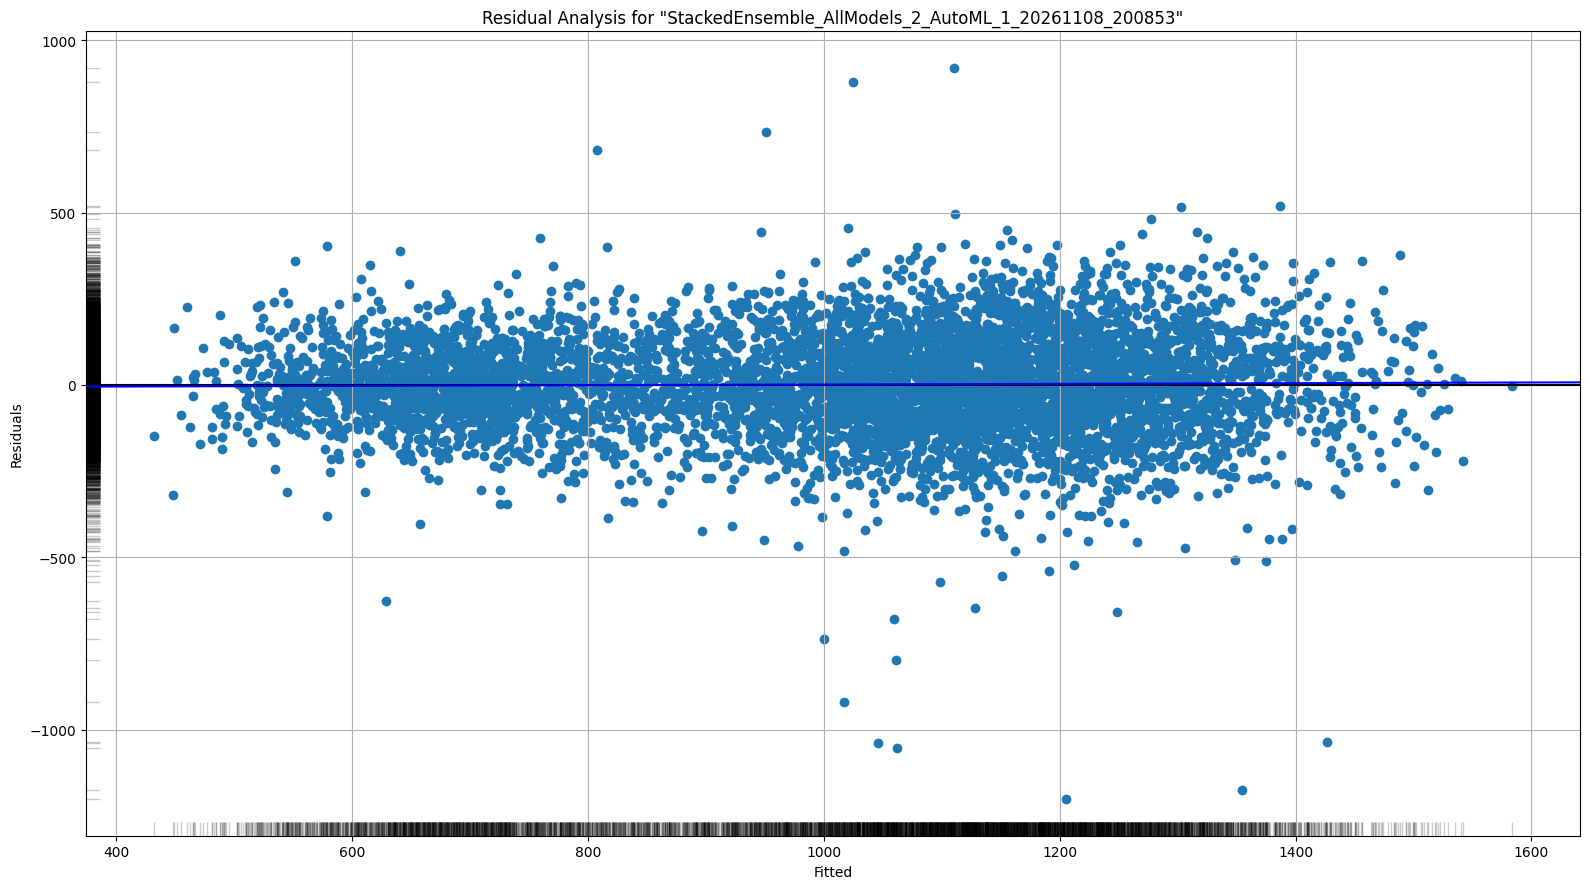

# Learning Curve Plot

> Learning curve plot shows the loss function/metric dependent on number of iterations or trees for tree-based algorithms. This plot can be useful for determining whether the model overfits.

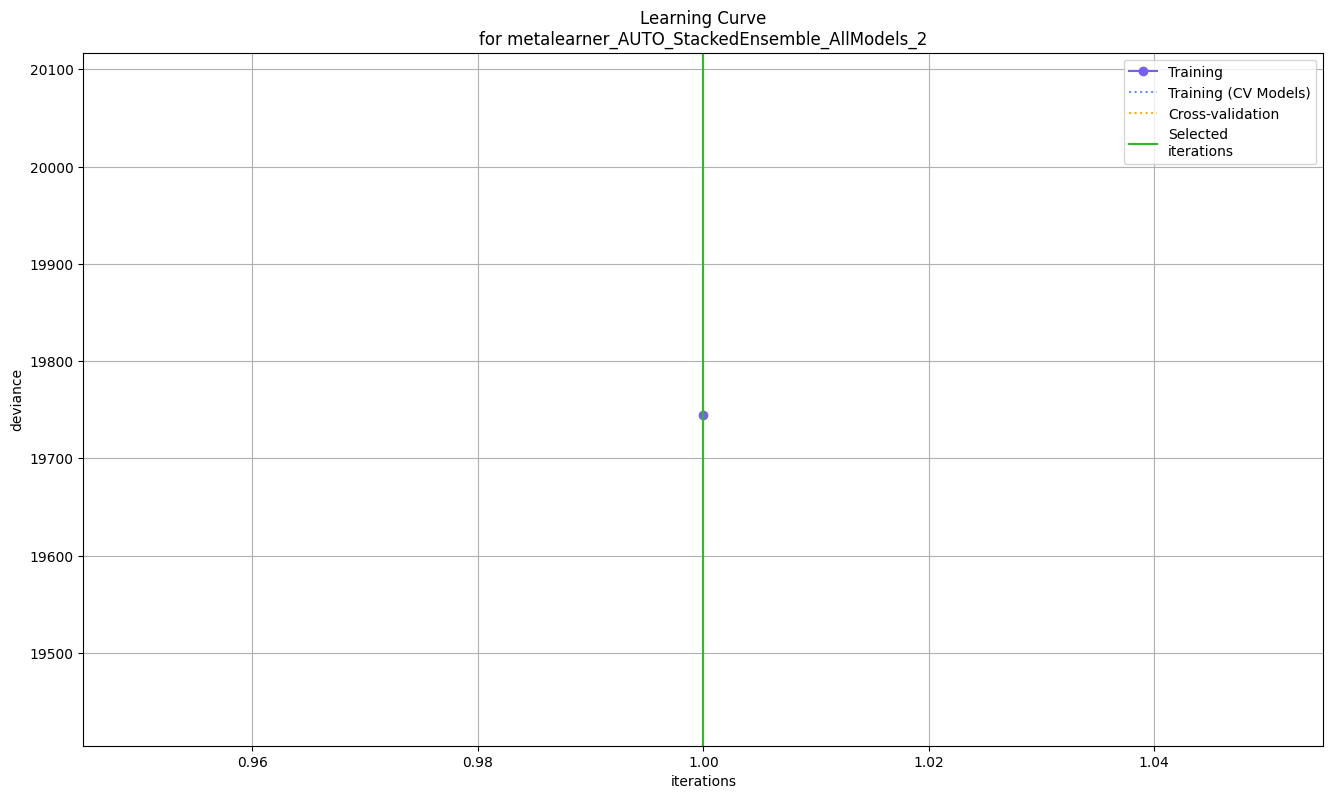

# Variable Importance

> The variable importance plot shows the relative importance of the most important variables in the model.

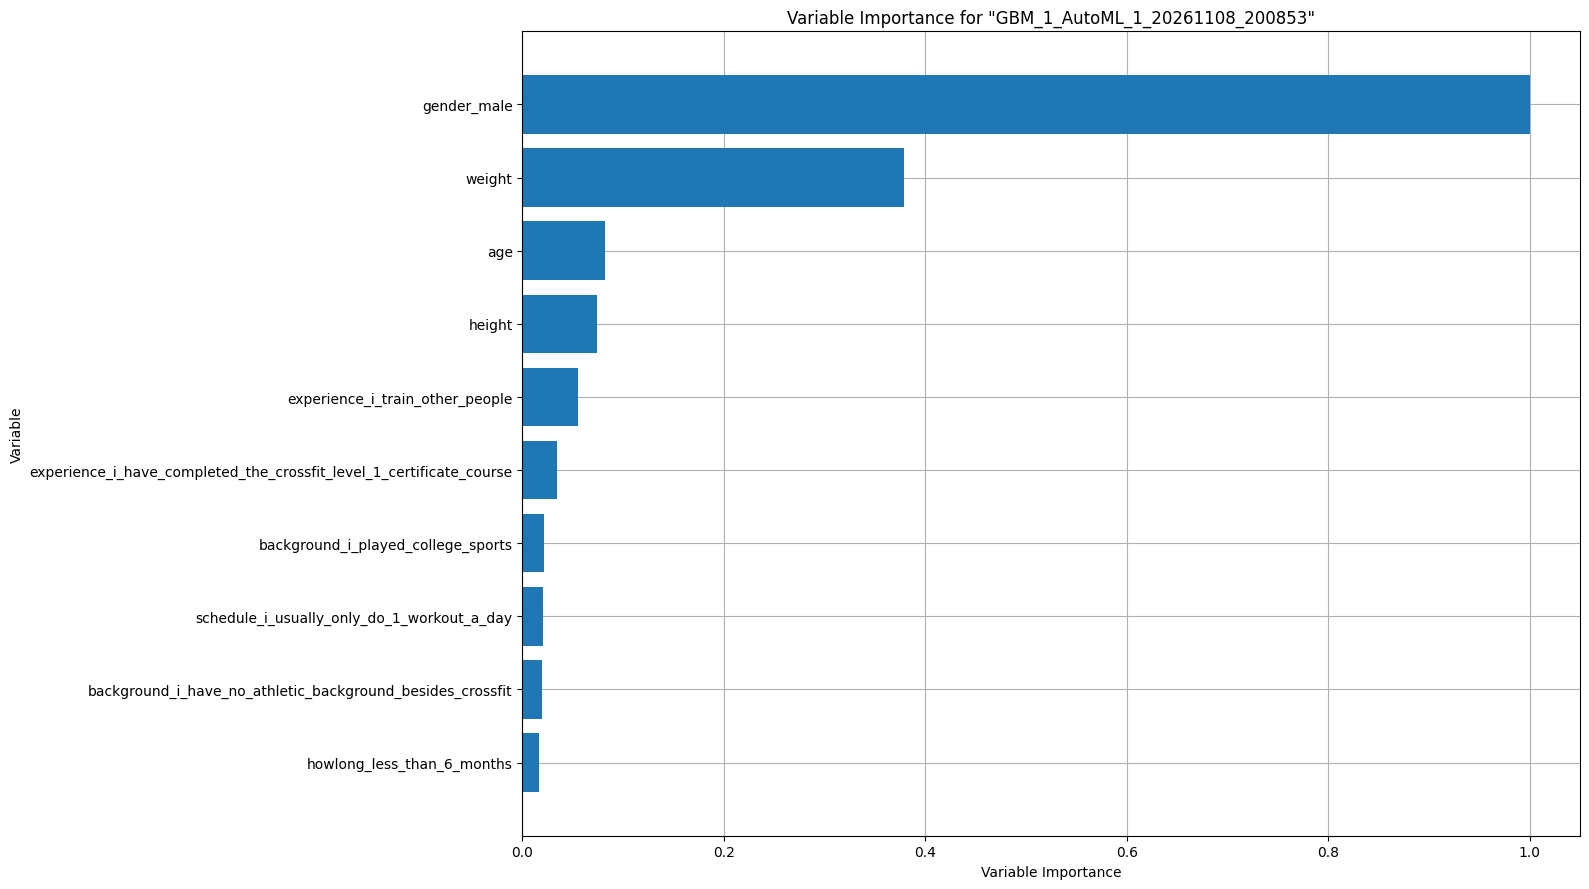

# Variable Importance Heatmap

> Variable importance heatmap shows variable importance across multiple models. Some models in H2O return variable importance for one-hot (binary indicator) encoded versions of categorical columns (e.g. Deep Learning, XGBoost). In order for the variable importance of categorical columns to be compared across all model types we compute a summarization of the the variable importance across all one-hot encoded features and return a single variable importance for the original categorical feature. By default, the models and variables are ordered by their similarity.

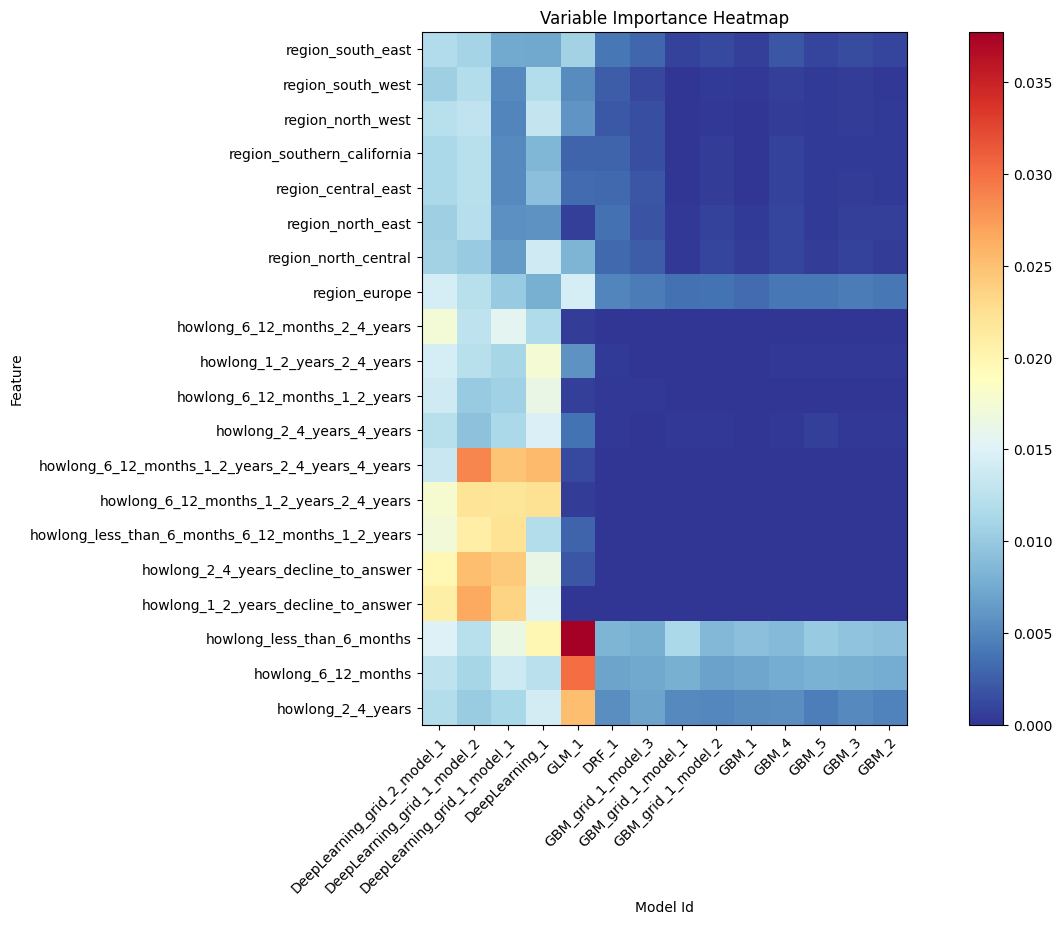

# Model Correlation

> This plot shows the correlation between the predictions of the models. For classification, frequency of identical predictions is used. By default, models are ordered by their similarity (as computed by hierarchical clustering). Interpretable models, such as GAM, GLM, and RuleFit are highlighted using red colored text.

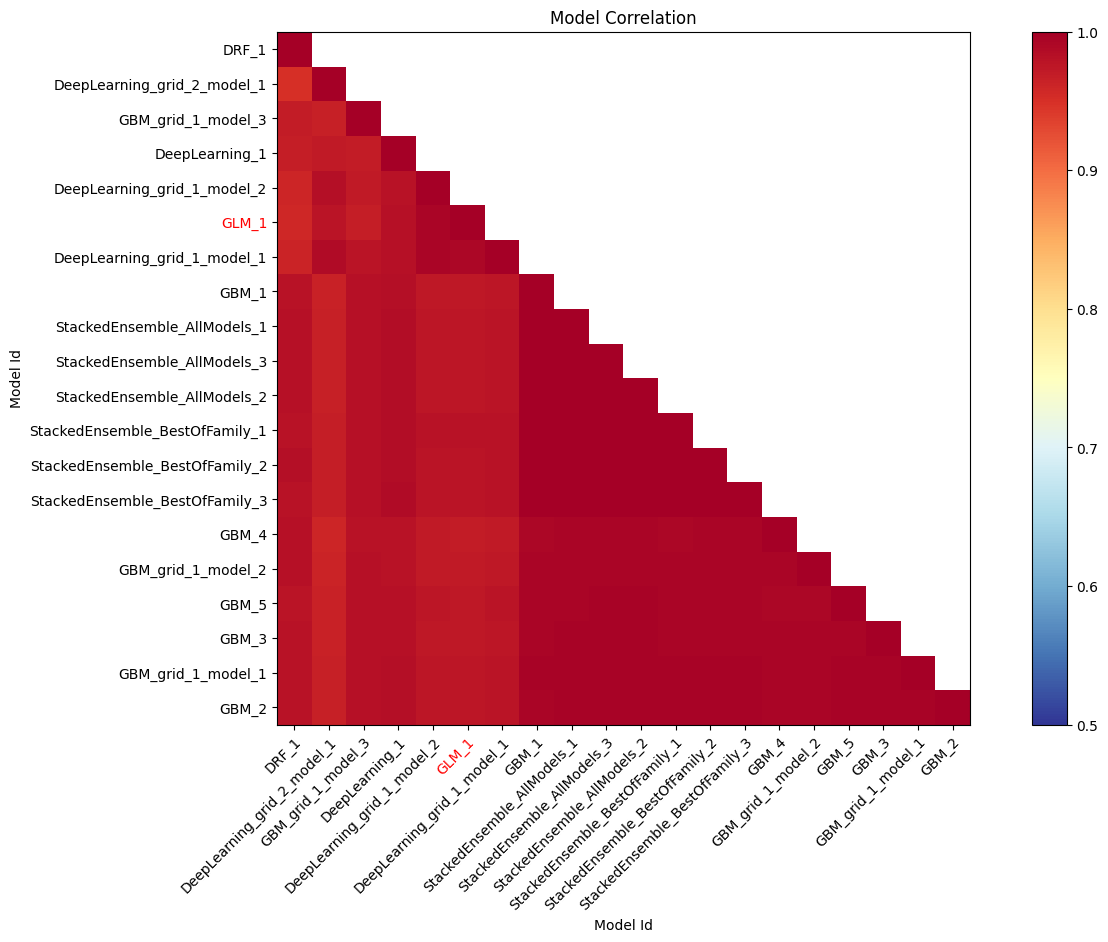

# SHAP Summary

> SHAP summary plot shows the contribution of the features for each instance (row of data). The sum of the feature contributions and the bias term is equal to the raw prediction of the model, i.e., prediction before applying inverse link function.

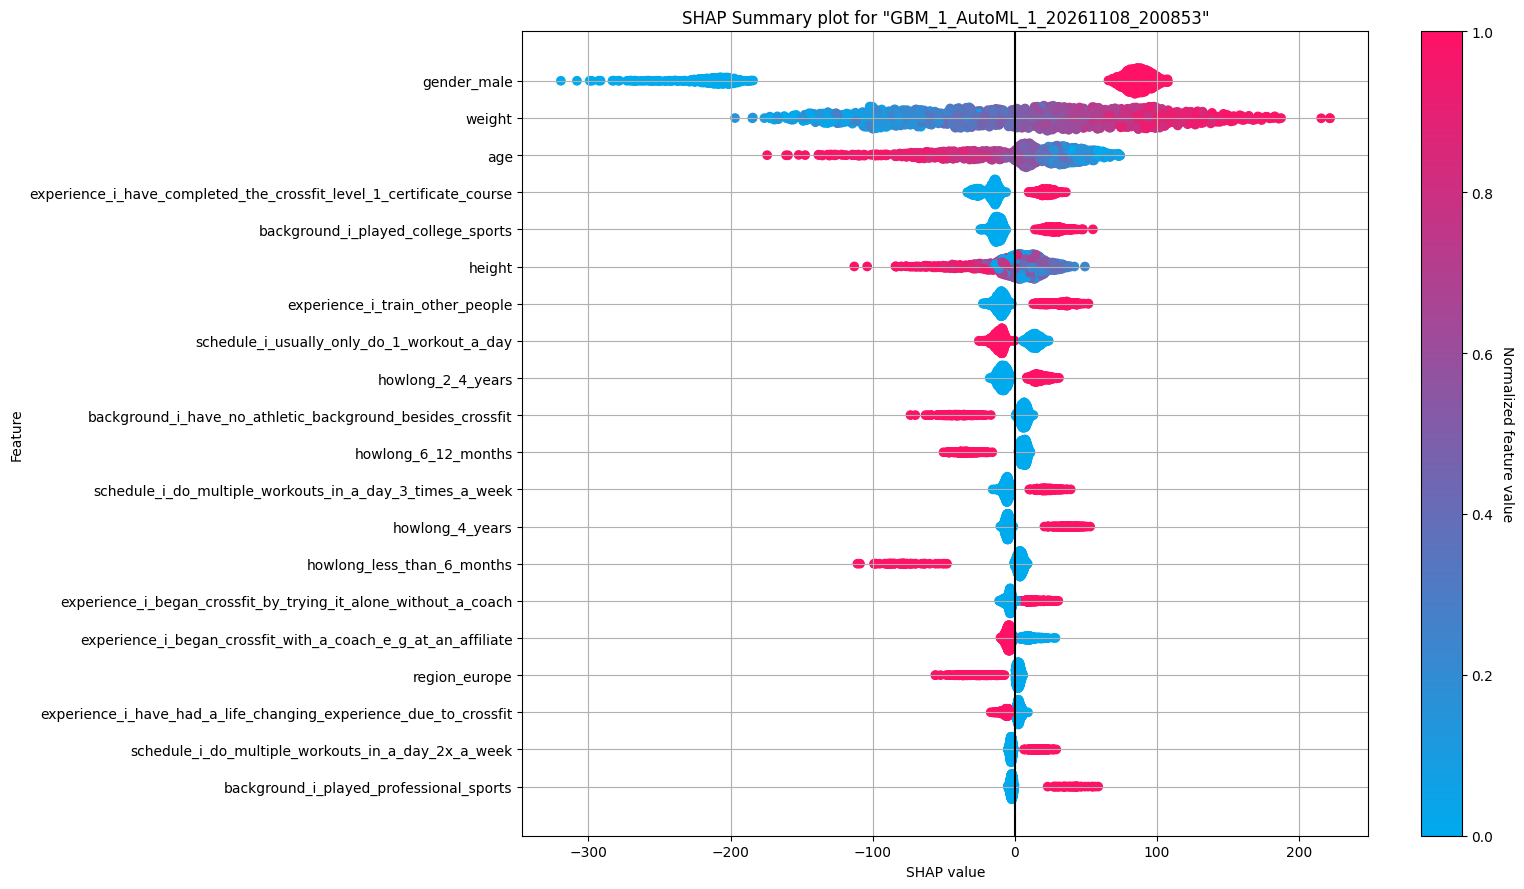

# Partial Dependence Plots

> Partial dependence plot (PDP) gives a graphical depiction of the marginal effect of a variable on the response. The effect of a variable is measured in change in the mean response. PDP assumes independence between the feature for which is the PDP computed and the rest.

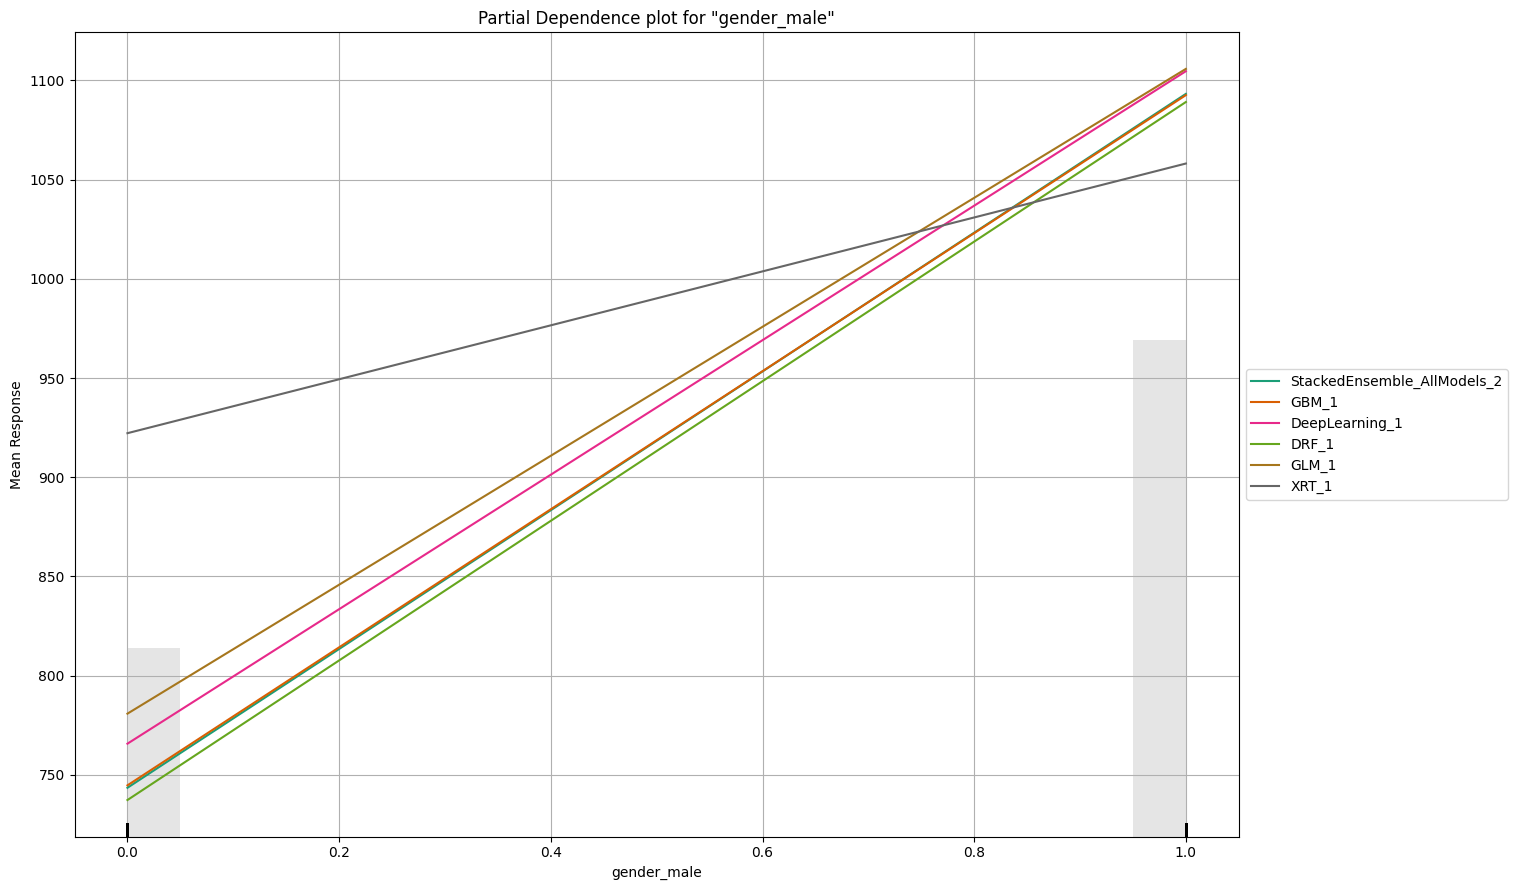

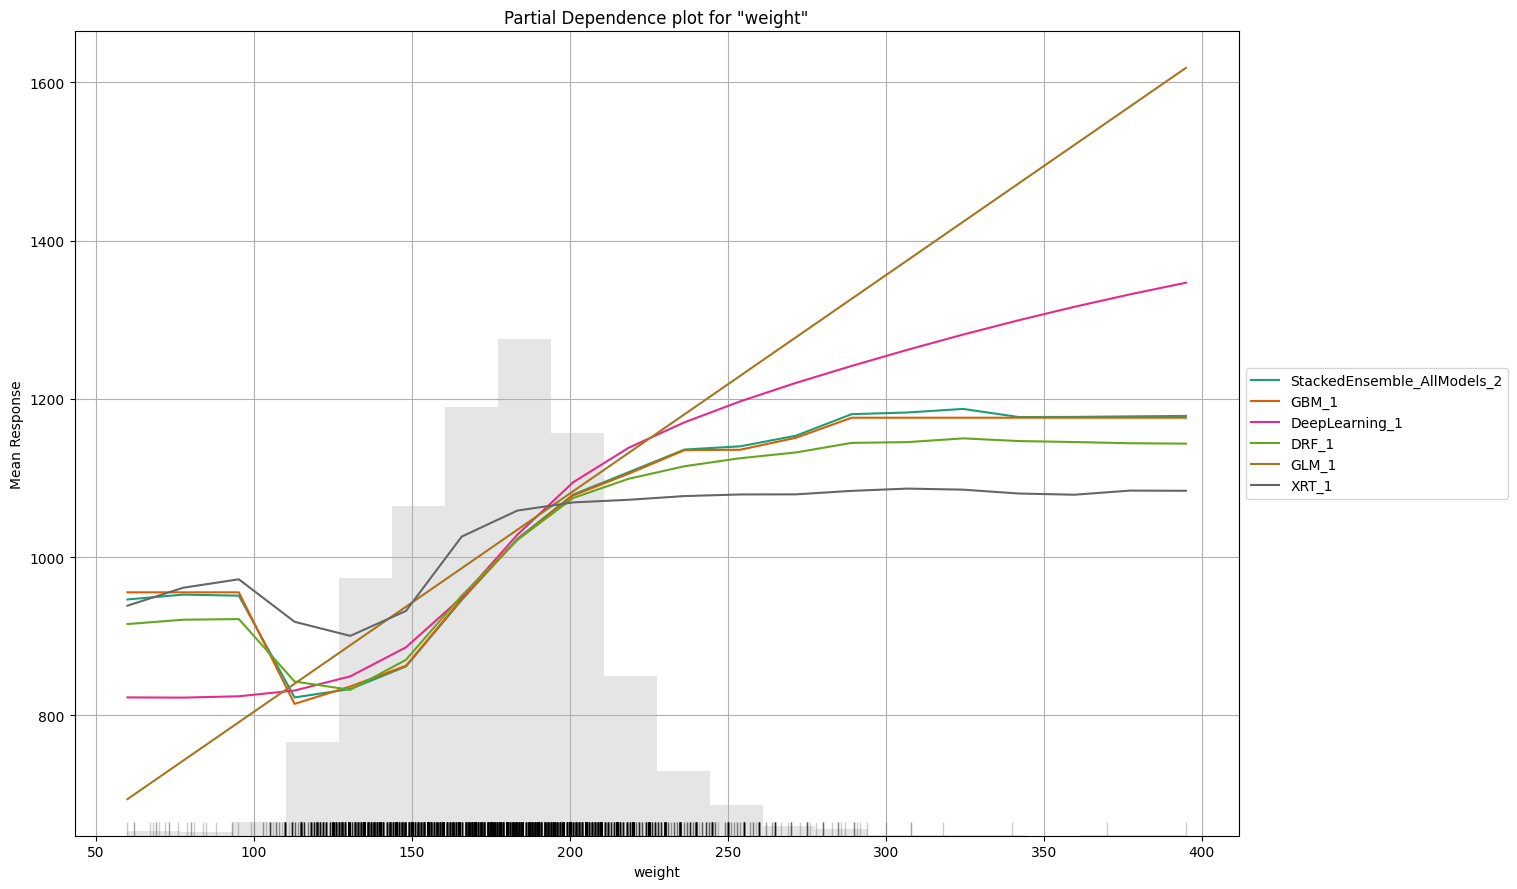

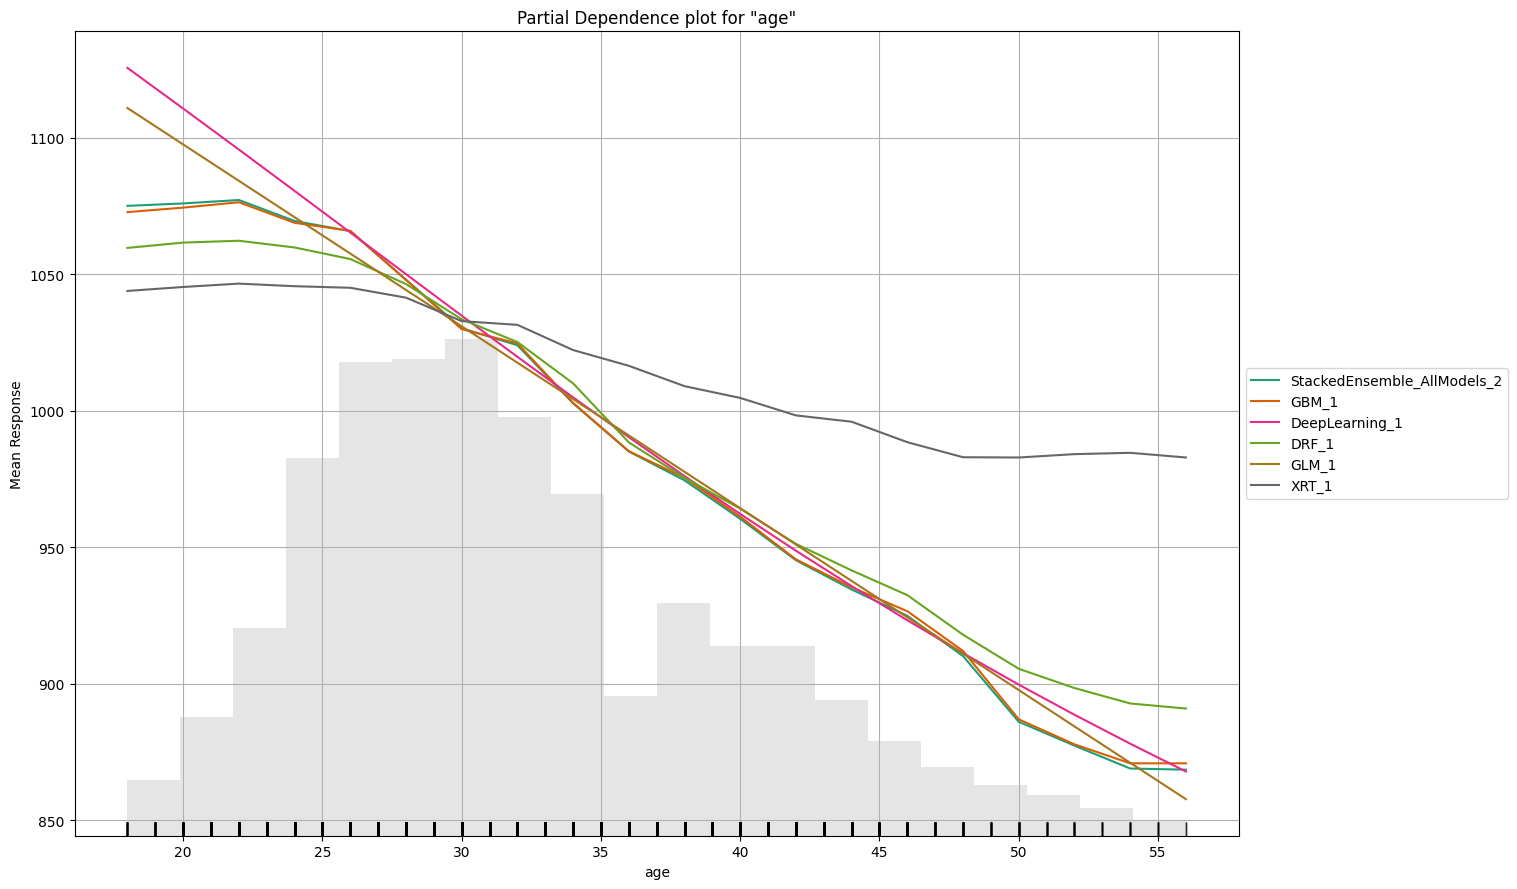

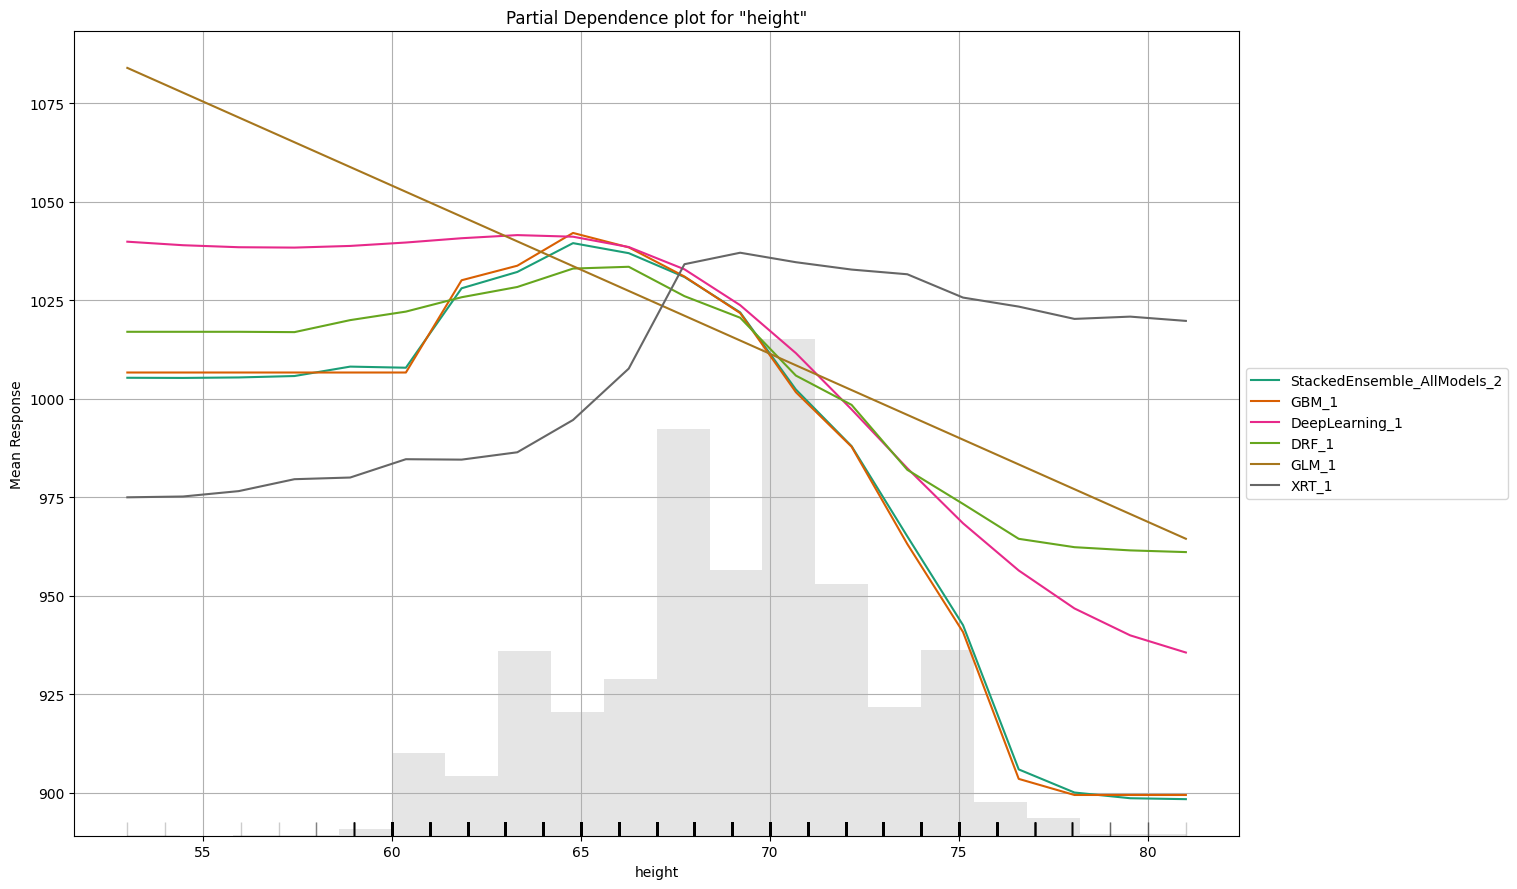

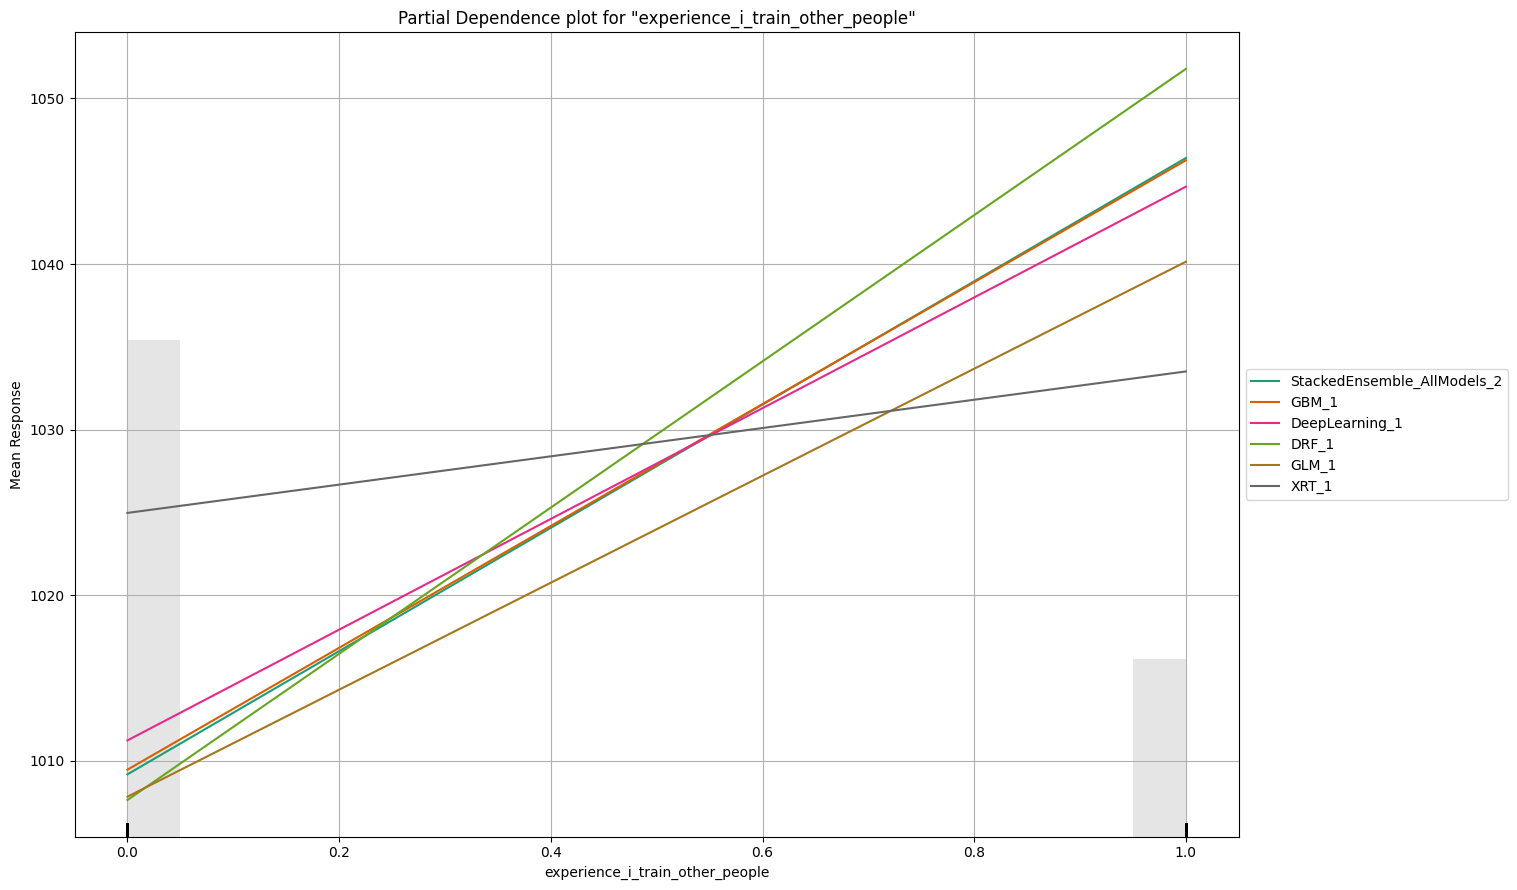

# Leaderboard

> Leaderboard shows models with their metrics. When provided with H2OAutoML object, the leaderboard shows 5-fold cross-validated metrics by default (depending on the H2OAutoML settings), otherwise it shows metrics computed on the frame. At most 20 models are shown by default.

model_id,rmse,mse,mae,rmsle,mean_residual_deviance,training_time_ms,predict_time_per_row_ms,algo
StackedEnsemble_BestOfFamily_3_AutoML_1_20261108_200853,144.729,20946.5,110.105,0.200197,20946.5,762,0.049019,StackedEnsemble
StackedEnsemble_AllModels_2_AutoML_1_20261108_200853,144.743,20950.5,110.091,0.200194,20950.5,720,0.035847,StackedEnsemble
StackedEnsemble_AllModels_3_AutoML_1_20261108_200853,144.763,20956.2,110.109,0.200208,20956.2,746,0.04879,StackedEnsemble
StackedEnsemble_AllModels_1_AutoML_1_20261108_200853,144.878,20989.7,110.224,0.200295,20989.7,688,0.04472,StackedEnsemble
StackedEnsemble_BestOfFamily_1_AutoML_1_20261108_200853,144.976,21018,110.372,0.200328,21018,649,0.030465,StackedEnsemble
StackedEnsemble_BestOfFamily_2_AutoML_1_20261108_200853,145.008,21027.4,110.401,0.200354,21027.4,707,0.041571,StackedEnsemble
GBM_1_AutoML_1_20261108_200853,145.266,21102.3,110.571,0.200637,21102.3,4141,0.044337,GBM
GBM_3_AutoML_1_20261108_200853,145.513,21174.1,110.757,0.20088,21174.1,4424,0.022532,GBM
GBM_5_AutoML_1_20261108_200853,145.603,21200.1,110.739,0.200989,21200.1,3998,0.03626,GBM
GBM_2_AutoML_1_20261108_200853,145.648,21213.4,110.715,0.201182,21213.4,3905,0.022507,GBM


# Residual Analysis

> Residual Analysis plots the fitted values vs residuals on a test dataset. Ideally, residuals should be randomly distributed. Patterns in this plot can indicate potential problems with the model selection, e.g., using simpler model than necessary, not accounting for heteroscedasticity, autocorrelation, etc. Note that if you see "striped" lines of residuals, that is an artifact of having an integer valued (vs a real valued) response variable.

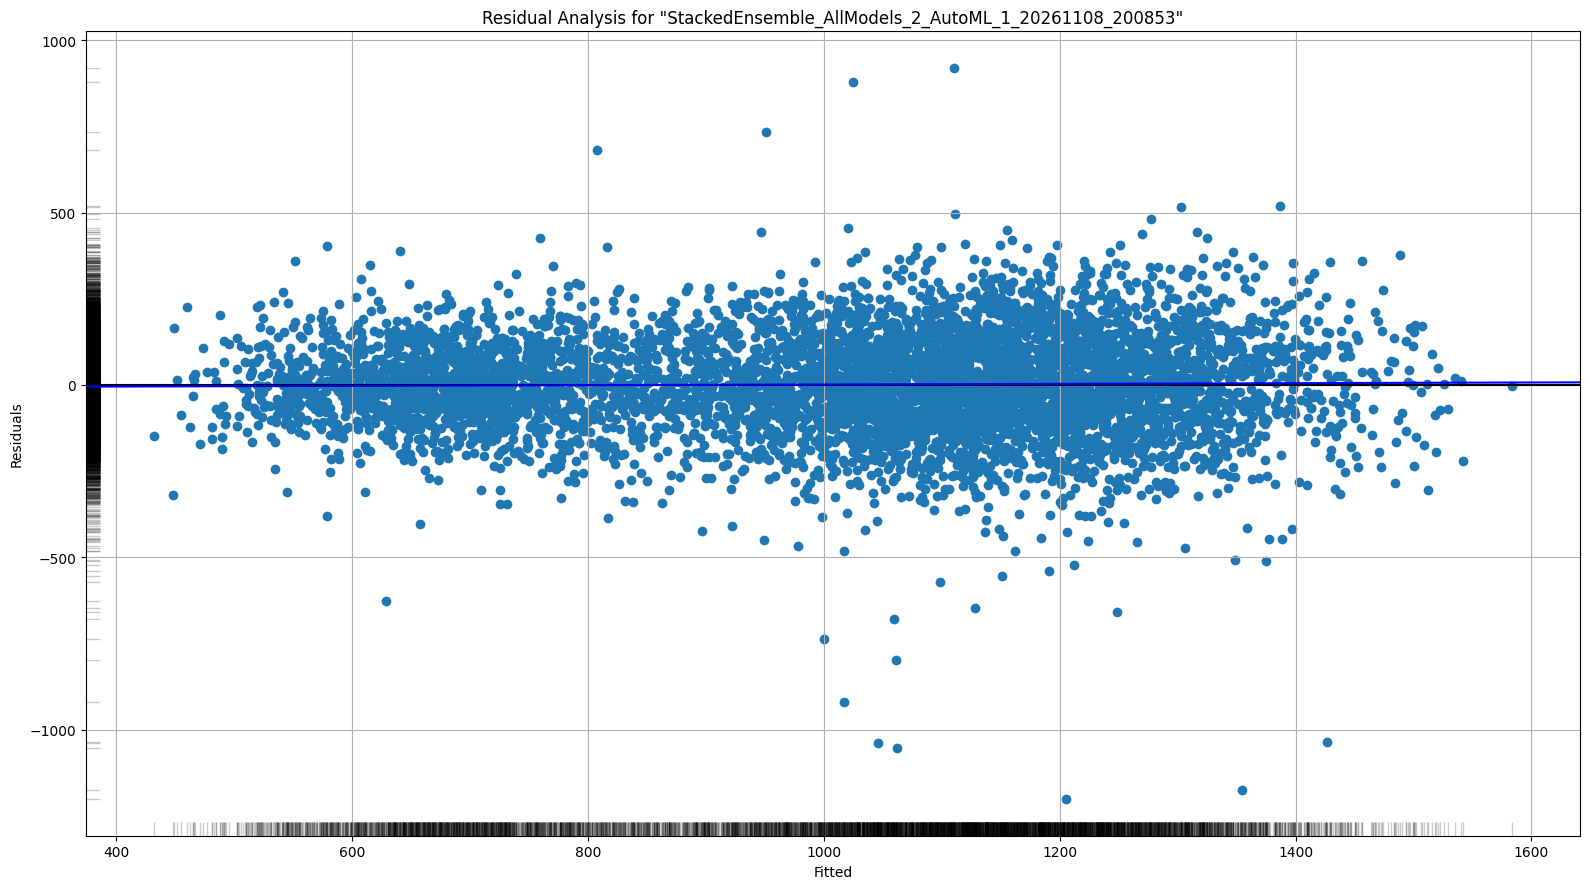

# Learning Curve Plot

> Learning curve plot shows the loss function/metric dependent on number of iterations or trees for tree-based algorithms. This plot can be useful for determining whether the model overfits.

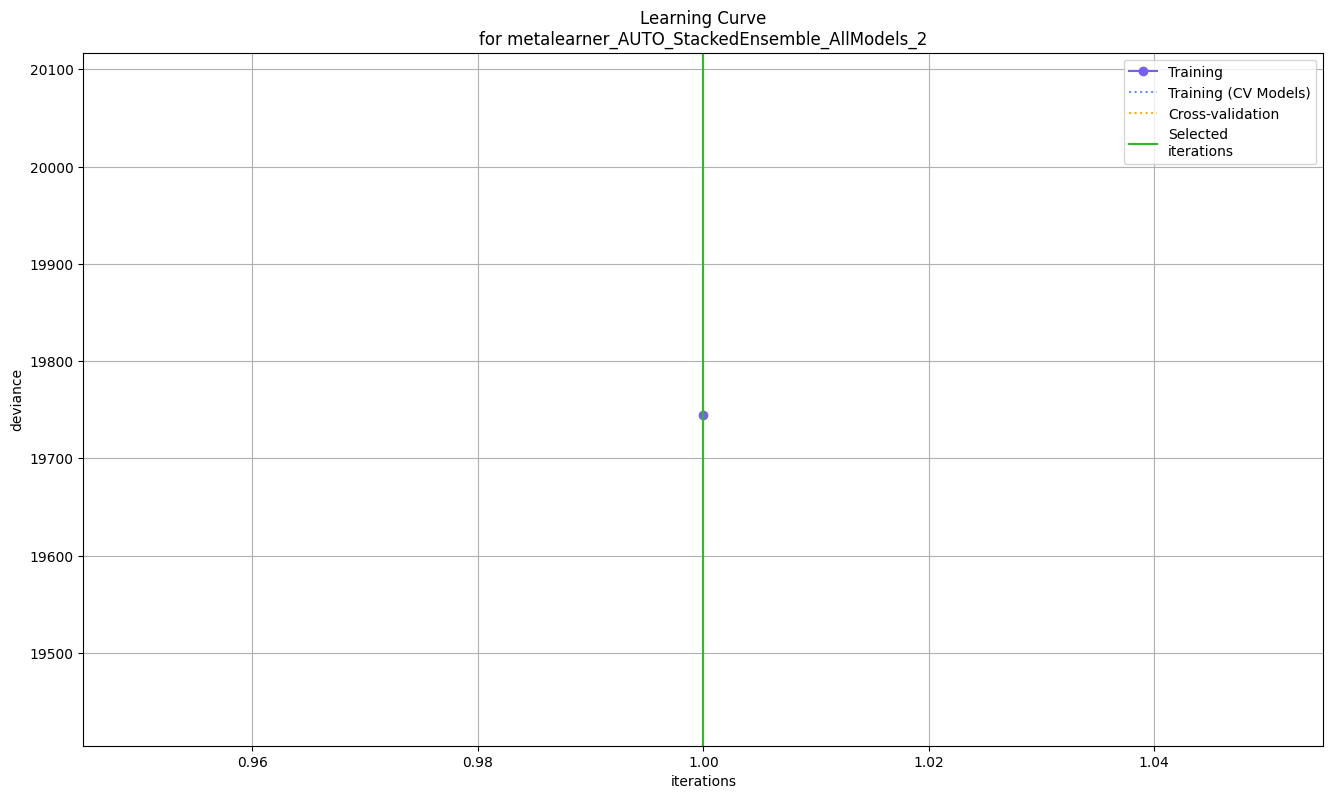

# Variable Importance

> The variable importance plot shows the relative importance of the most important variables in the model.

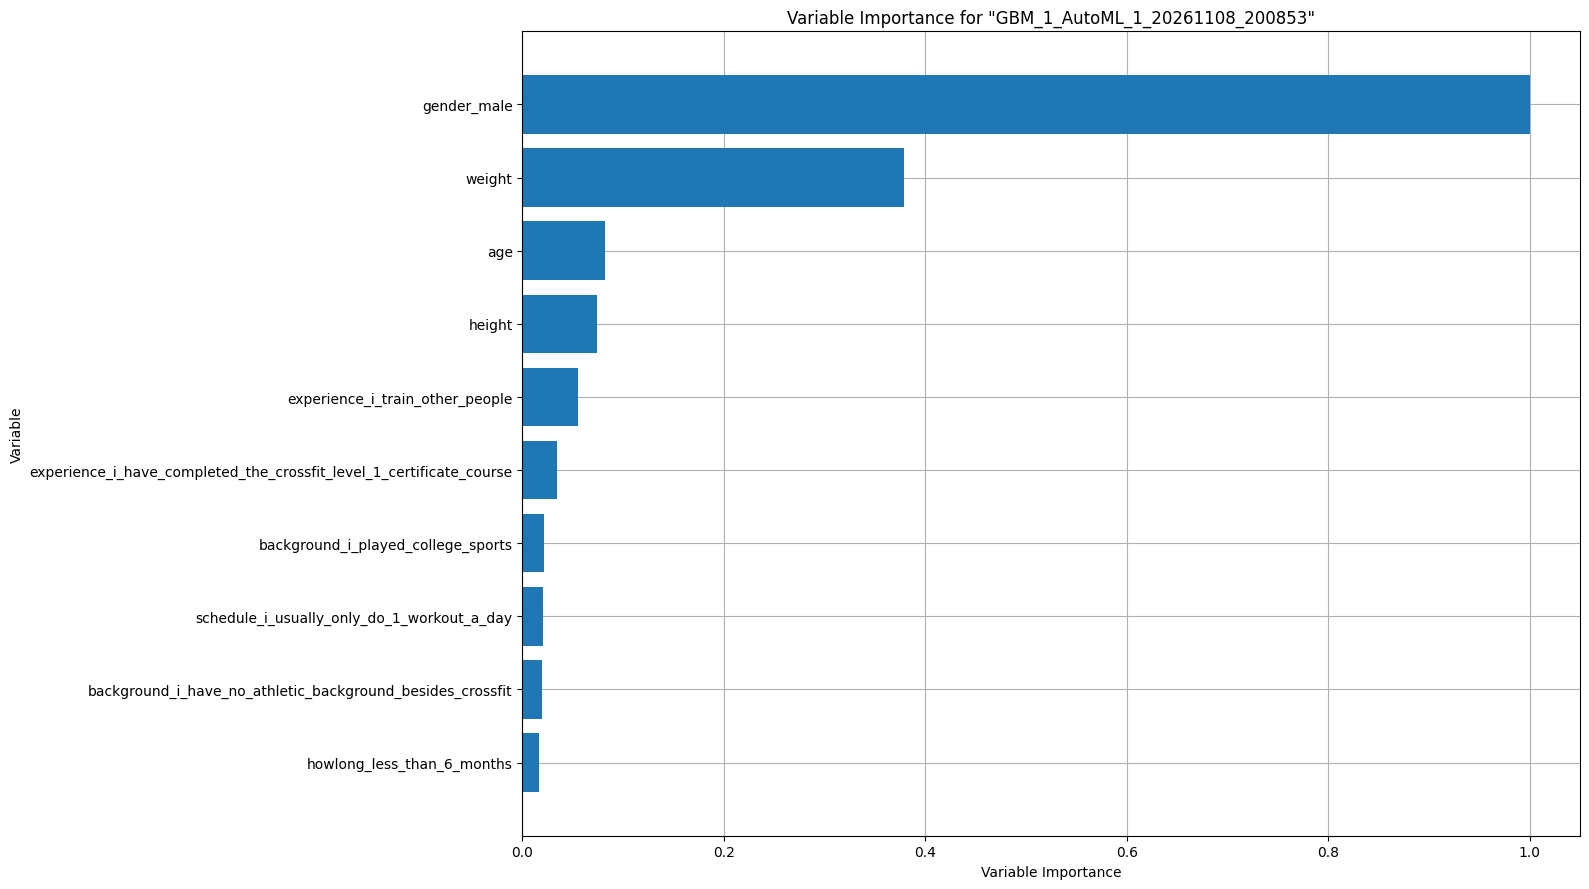

# Variable Importance Heatmap

> Variable importance heatmap shows variable importance across multiple models. Some models in H2O return variable importance for one-hot (binary indicator) encoded versions of categorical columns (e.g. Deep Learning, XGBoost). In order for the variable importance of categorical columns to be compared across all model types we compute a summarization of the the variable importance across all one-hot encoded features and return a single variable importance for the original categorical feature. By default, the models and variables are ordered by their similarity.

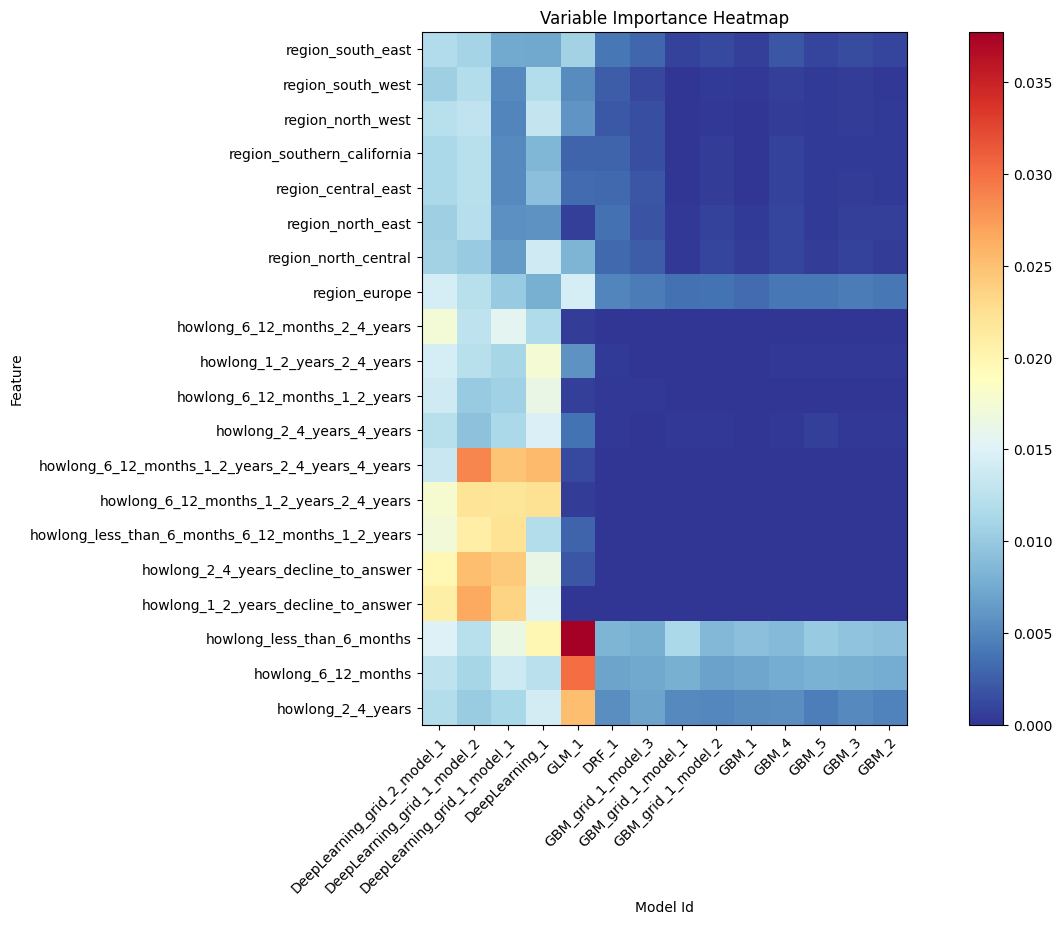

# Model Correlation

> This plot shows the correlation between the predictions of the models. For classification, frequency of identical predictions is used. By default, models are ordered by their similarity (as computed by hierarchical clustering). Interpretable models, such as GAM, GLM, and RuleFit are highlighted using red colored text.

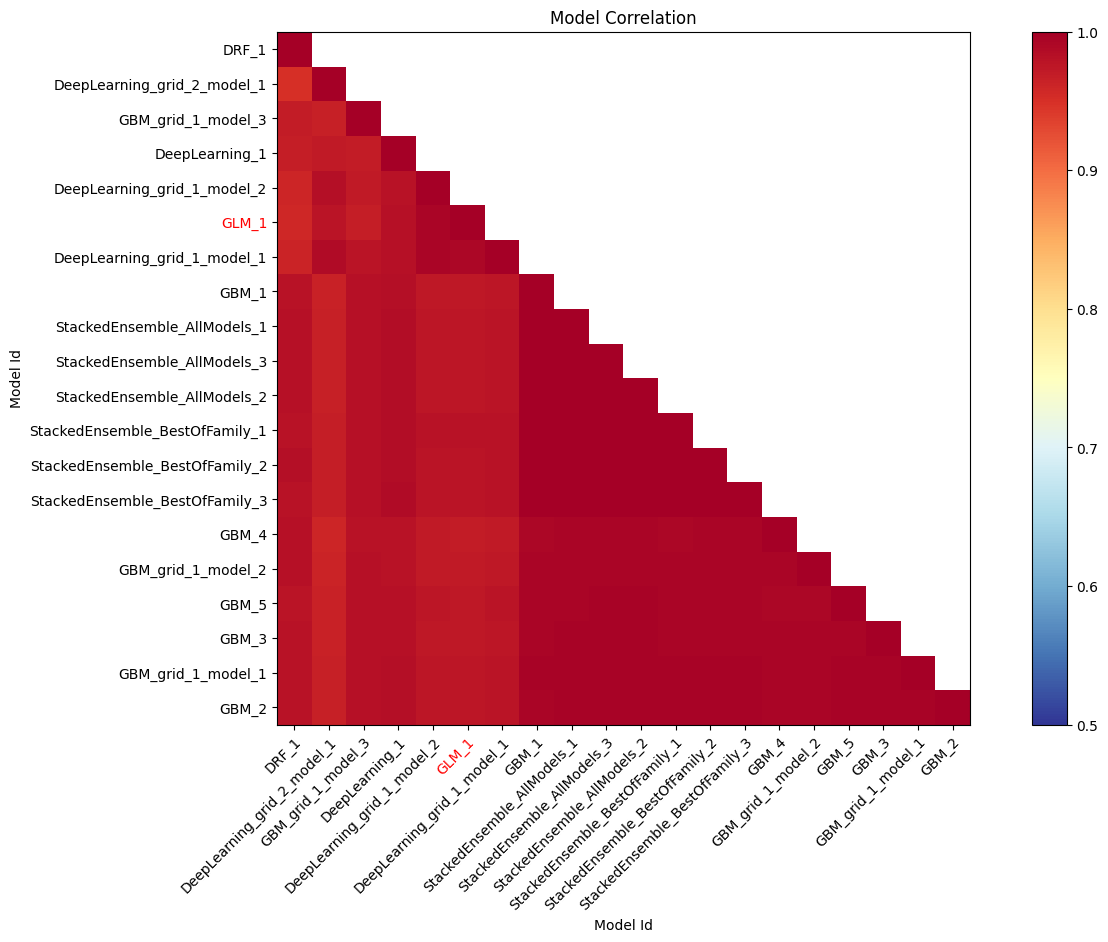

# SHAP Summary

> SHAP summary plot shows the contribution of the features for each instance (row of data). The sum of the feature contributions and the bias term is equal to the raw prediction of the model, i.e., prediction before applying inverse link function.

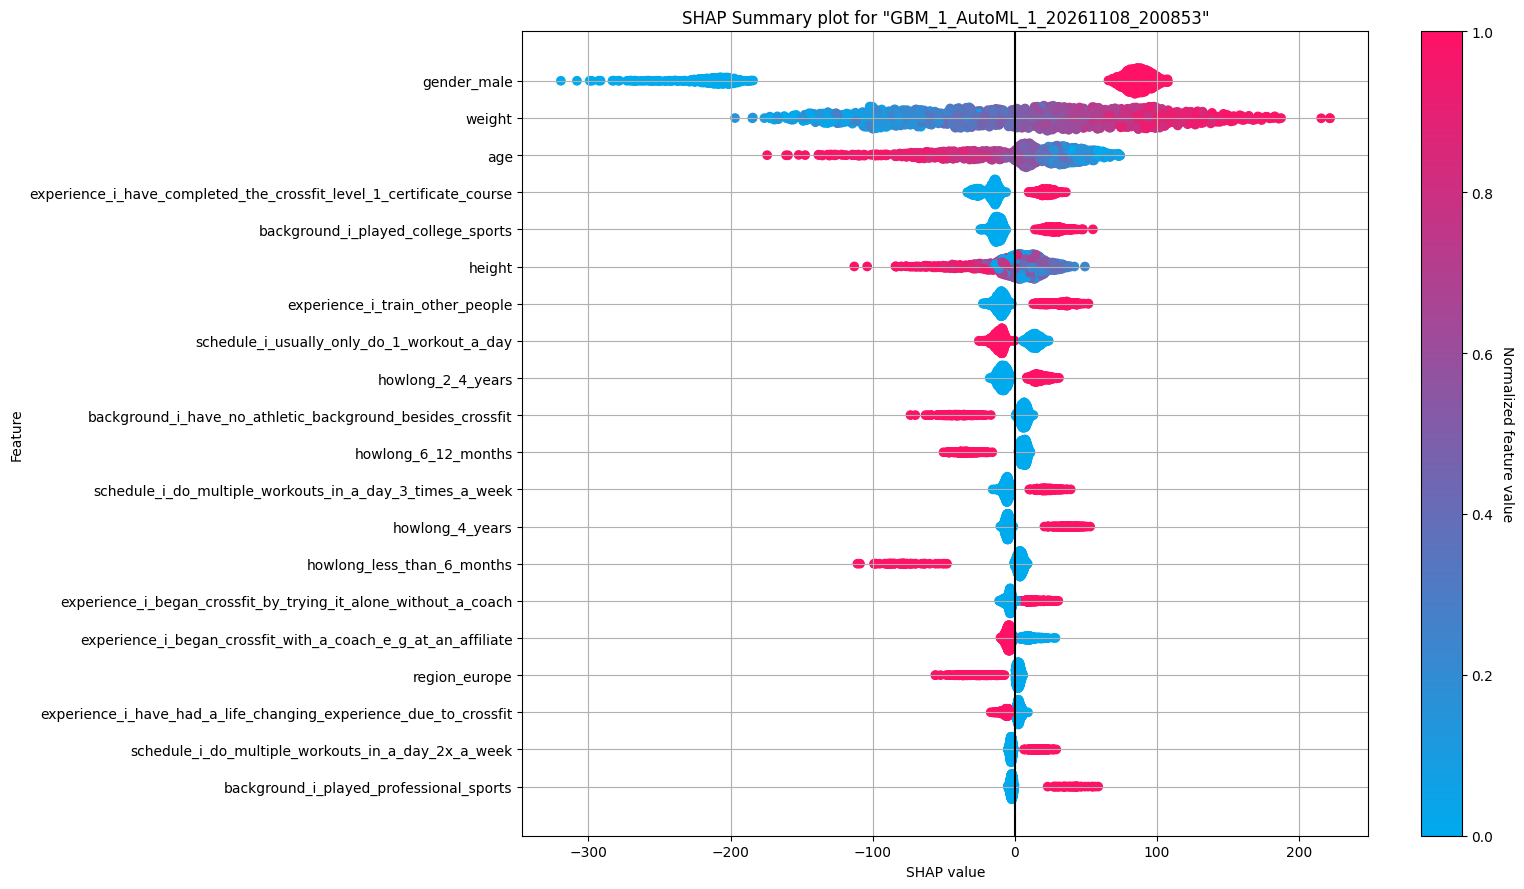

# Partial Dependence Plots

> Partial dependence plot (PDP) gives a graphical depiction of the marginal effect of a variable on the response. The effect of a variable is measured in change in the mean response. PDP assumes independence between the feature for which is the PDP computed and the rest.

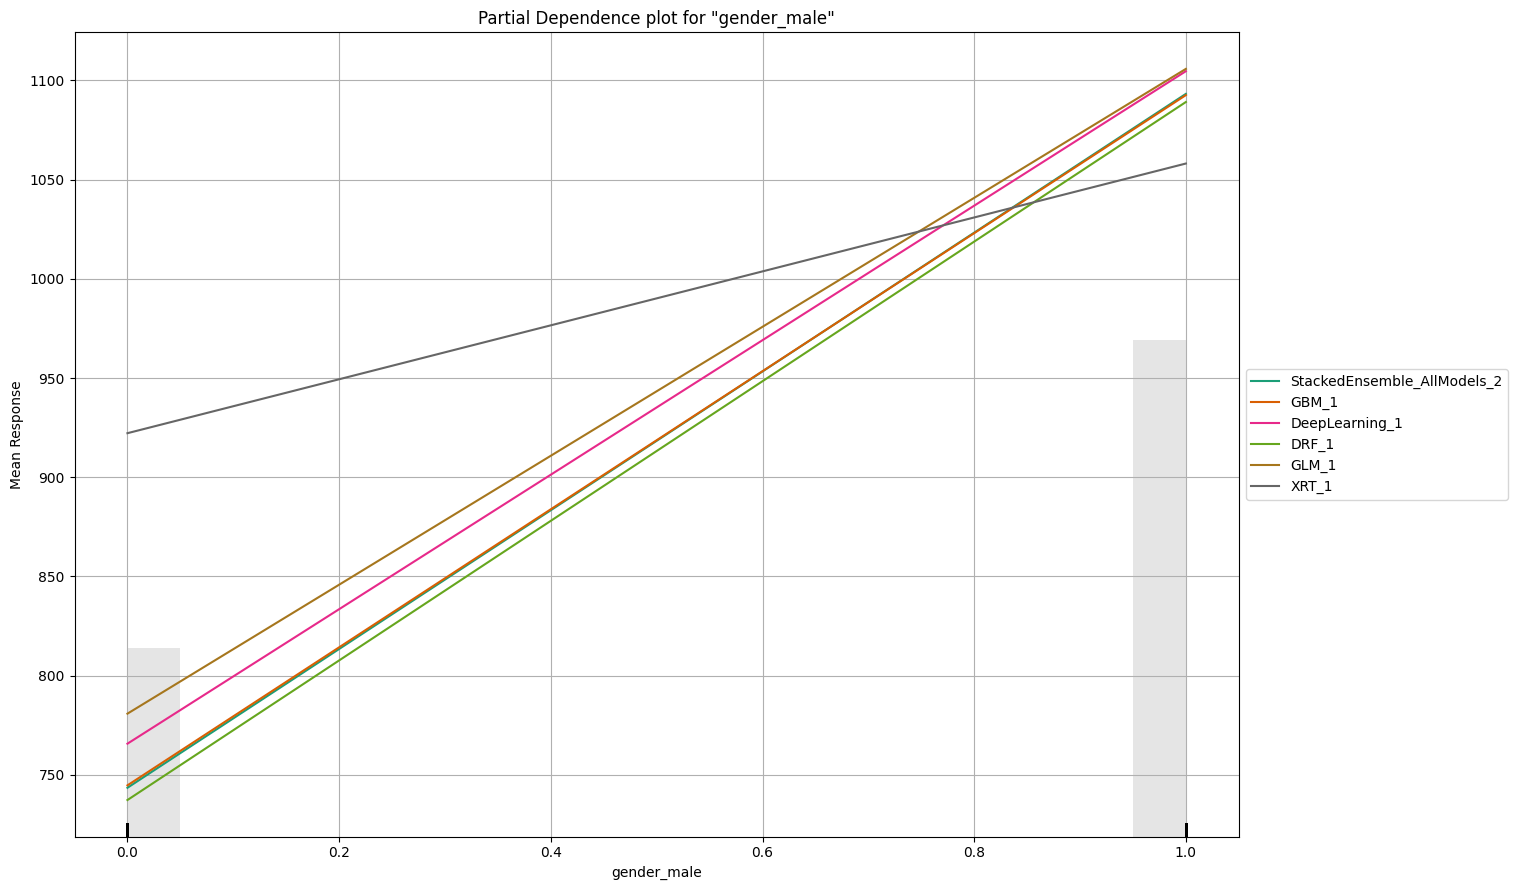

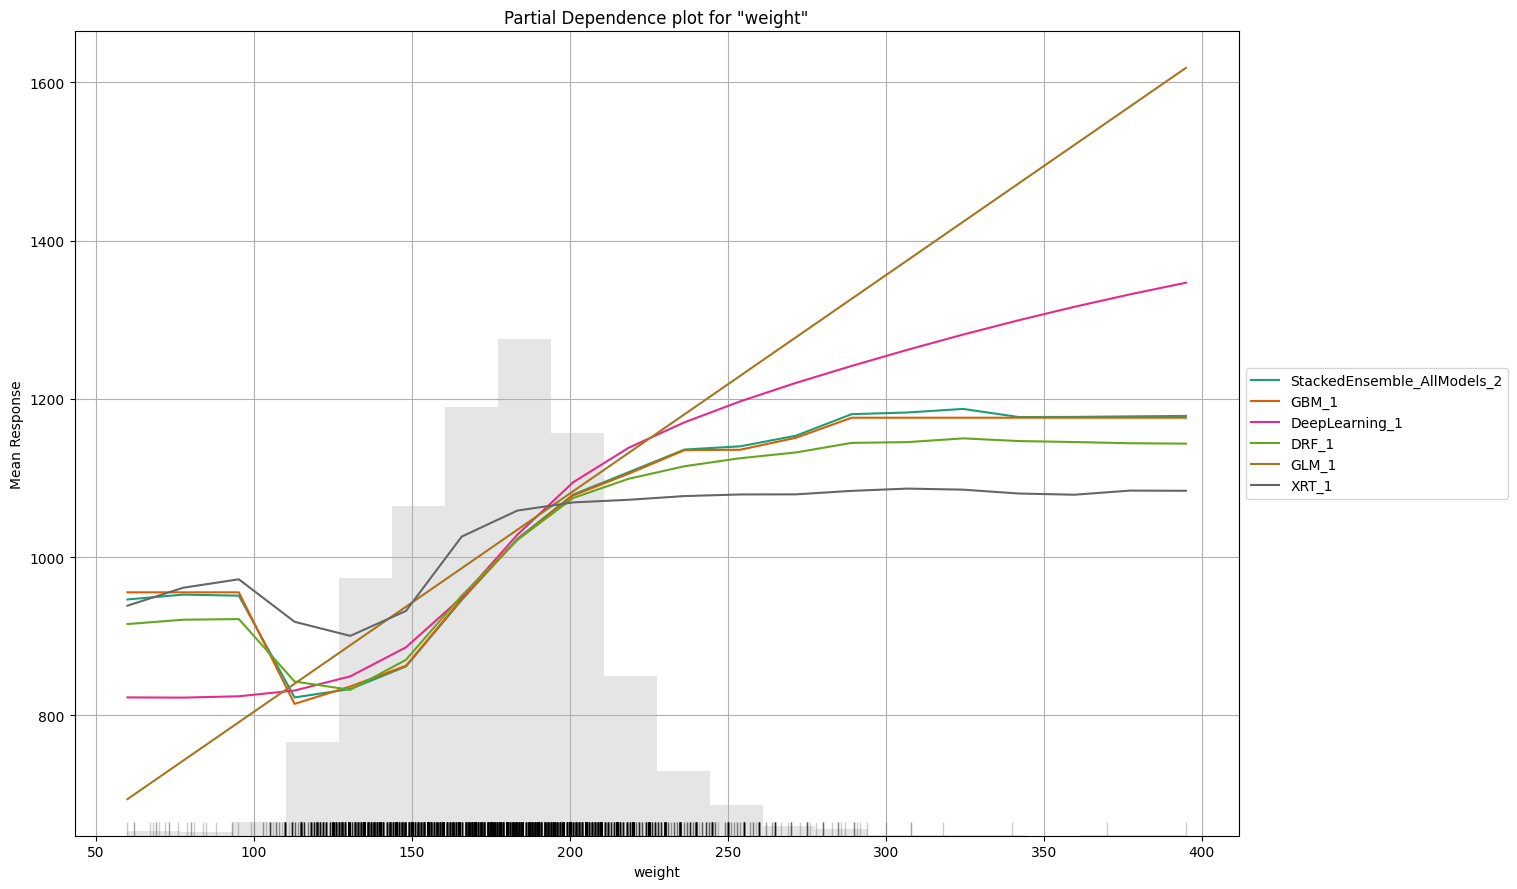

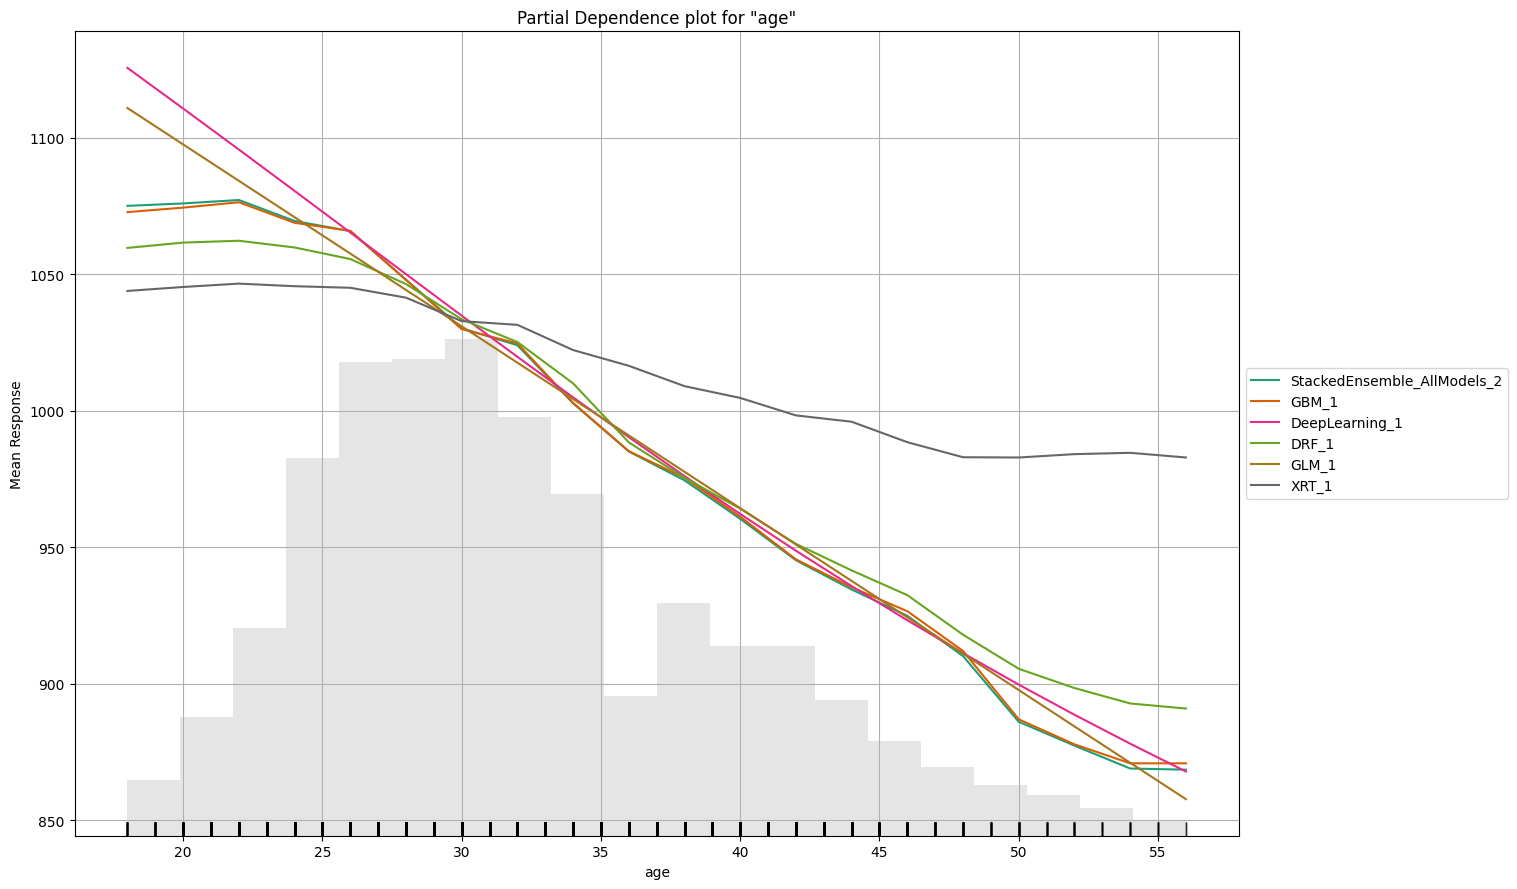

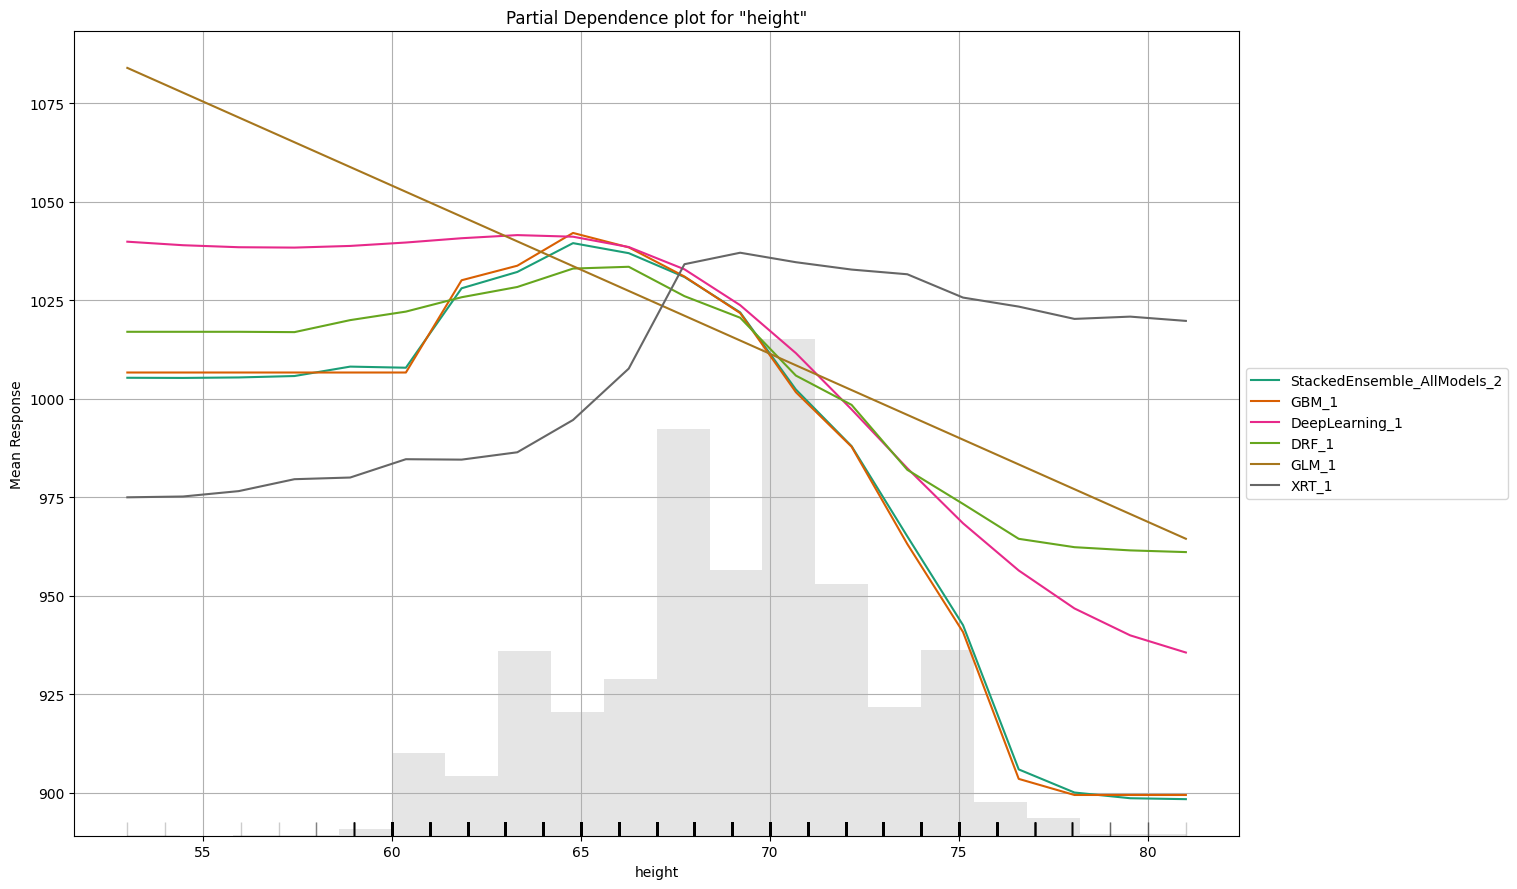

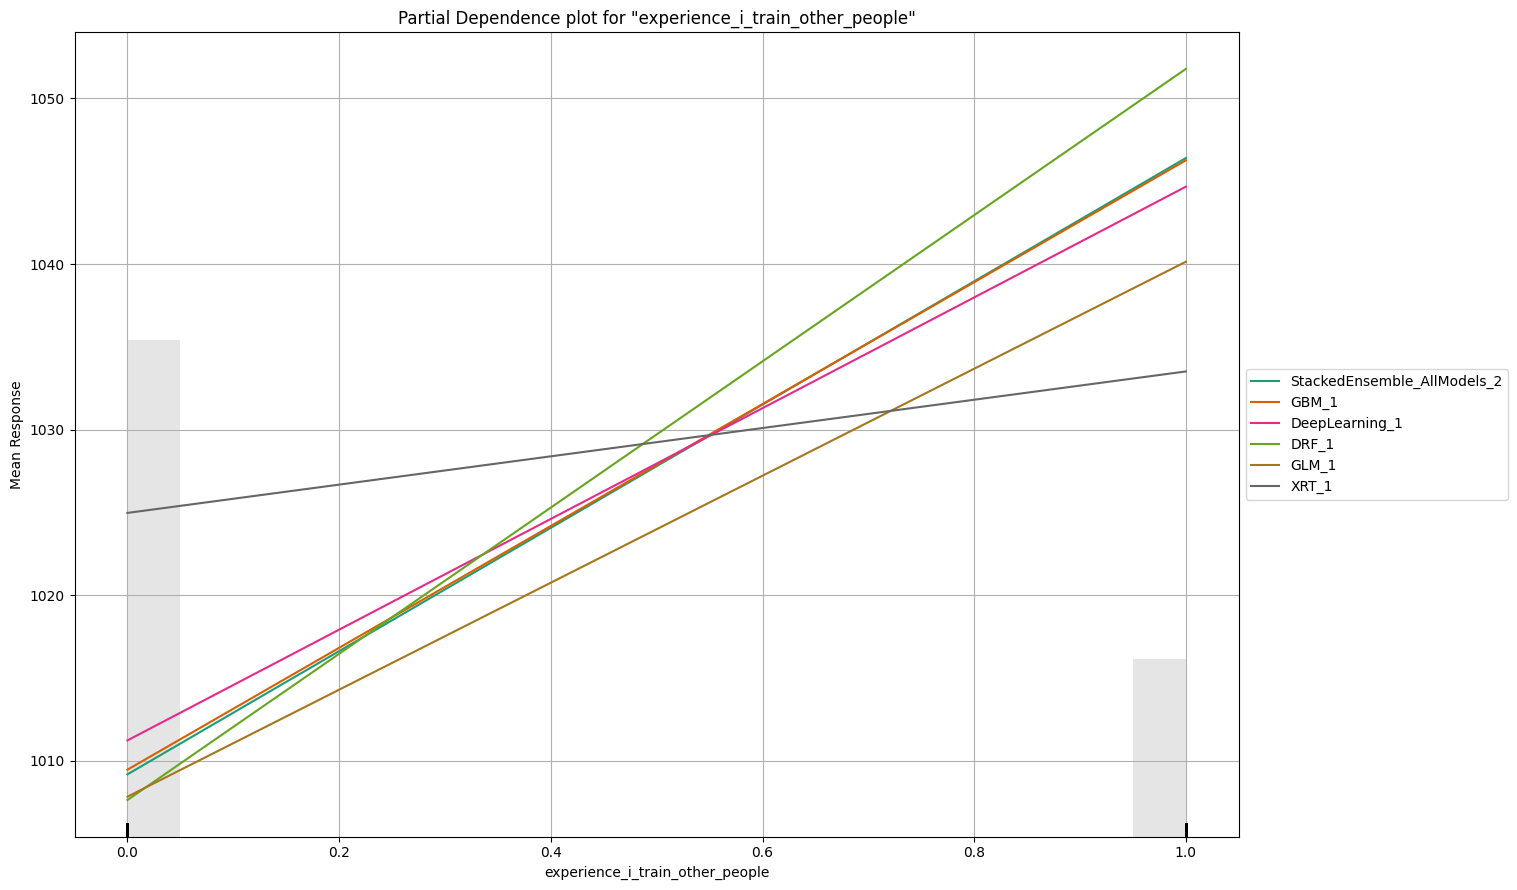

In [6]:
aml_all.explain(hf_test, exclude_explanations=["ice"])
# Includes: leaderboard, residual analysis, variable importance (+ heatmap across models),
# model correlation heatmap, SHAP summary, and partial dependence plots.

## 4. Top 5 features

Stacked ensembles don't report variable importance, so this uses the best individual (non-ensemble) model.

Best non-ensemble model: GBM_1_AutoML_1_20261108_200853


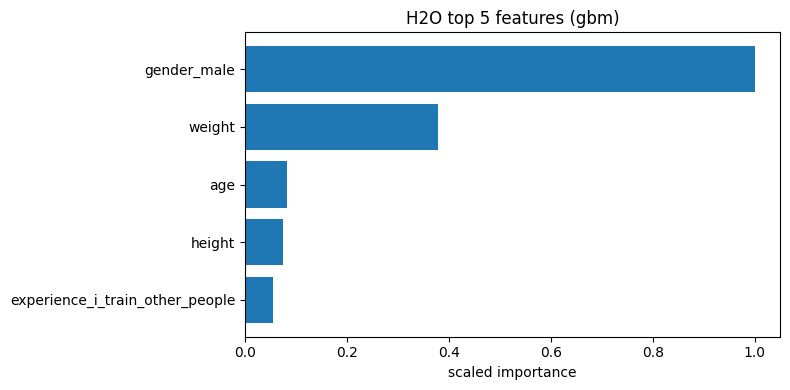

,variable,relative_importance,scaled_importance,percentage
0,gender_male,4.044715e+09,1.000000,0.551221
1,weight,1.533202e+09,0.379063,0.208947
2,age,3.311521e+08,0.081873,0.045130
3,height,2.984761e+08,0.073794,0.040677
4,experience_i_train_other_people,2.217436e+08,0.054823,0.030220


In [7]:
best_base = aml_all.get_best_model(algorithm="basemodel")
print("Best non-ensemble model:", best_base.model_id)

vi = best_base.varimp(use_pandas=True)
top5 = vi.head(5)[["variable", "relative_importance", "scaled_importance", "percentage"]]
top5.to_csv(RESULTS / "h2o_top5_features.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top5["variable"][::-1], top5["scaled_importance"][::-1])
ax.set(title=f"H2O top 5 features ({best_base.algo})", xlabel="scaled importance")
fig.tight_layout()
fig.savefig(RESULTS / "h2o_top5_features.png", dpi=150)
plt.show()
top5

## 5. Top 3 models by validation score (5-fold CV RMSE)

### 5.1 All features

In [8]:
cols = ["model_id", "rmse", "mae", "mean_residual_deviance"]
lb_all.head(3)[cols]

,model_id,rmse,mae,mean_residual_deviance
0,StackedEnsemble_AllModels_2_AutoML_1_20261108_...,140.524912,107.313765,19747.250902
1,StackedEnsemble_AllModels_3_AutoML_1_20261108_...,140.537395,107.324255,19750.759484
2,StackedEnsemble_AllModels_1_AutoML_1_20261108_...,140.657343,107.422452,19784.488198


### 5.2 Only the top 3 features

In [9]:
top3_feats = list(top5["variable"].head(3))
print("Top 3 features:", top3_feats)

aml_top, lb_top = run_automl(top3_feats, "athletes_h2o_top3_features")
lb_top.to_csv(RESULTS / "h2o_leaderboard_top3_features.csv", index=False)
lb_top.head(3)[cols]

Top 3 features: ['gender_male', 'weight', 'age']
AutoML progress: |
20:16:05.724: AutoML: XGBoost is not available; skipping it.

███████████████████████████████████████████████████████████████| (done) 100%


/Users/johnhenryoliphant/miniconda3/envs/automl/lib/python3.11/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


,model_id,rmse,mae,mean_residual_deviance
0,StackedEnsemble_BestOfFamily_4_AutoML_2_202611...,170.006504,132.404167,28902.211446
1,StackedEnsemble_AllModels_3_AutoML_2_20261108_...,170.035051,132.429950,28911.918738
2,GBM_grid_1_AutoML_2_20261108_201605_model_5,170.046031,132.446964,28915.652748


In [10]:
h2o.cluster().shutdown()

H2O session _sid_894e closed.
